# classify_commission_documents_v8

Candidate-level Gemma validation of the three Commission regex families.

## v8 design

The unit of classification is:

> **one Commission document × one family × one normalized regex candidate**

If `C-22/10` occurs 100 times in one document, v8 creates **one Court-case job** for
`C-22/10`. That one prepared input contains all 100 occurrence windows.

The three families remain completely separate because their legal/identifier semantics differ:

1. `court_case`
2. `commission_reference`
3. `commission_case`

## What is sent to Gemma

Before any inference starts, v8 creates disk-backed text inputs under:

```text
data/temp/commission_registry/
    court_case/
    commission_reference/
    commission_case/
```

Each candidate-level input contains:

- the first **10,000 characters** of the source document;
- the last **5,000 characters** of the source document;
- **1,000 characters before and 1,000 characters after every occurrence** of that
  normalized candidate in that document;
- explicit labels for every occurrence, including the raw regex match and original
  character positions.

Occurrence windows are intentionally kept as separate sections. v8 does **not**
split a candidate across multiple LLM requests and does **not** defer large source
documents. A warning is emitted for unusually large prepared inputs, but the job
remains runnable.

## What Gemma is asked to do

Gemma is **not** asked to scan the document exhaustively for missed identifiers.
Regex has already done retrieval.

For the one supplied candidate it must decide:

1. whether the candidate is genuinely an identifier of the current family in this document;
2. which canonical identifier(s) are represented by citation expressions containing
   that candidate across the supplied occurrences.

This includes obvious coordinated expressions such as `and`, `or`, comma lists,
shared prefixes/years/suffixes, and ranges such as:

```text
C-22/10 to 25/10
```

which should resolve to:

```text
C-22/10
C-23/10
C-24/10
C-25/10
```

The LLM output is deliberately tiny: `valid` plus `identifiers`.

## Execution model

1. Load the three family `raw_hits` sheets.
2. Build **all prepared input files first** with `tqdm`.
3. Build lightweight job dictionaries from the disk-backed registry.
4. Run the three families independently with specialised prompts.
5. Append every result immediately to family-specific v8 JSONL checkpoints.
6. Rebuild candidate-level and exploded identifier exports from the checkpoints.

The preparation and inference phases are deliberately separate so that preprocessing
can be inspected before any GPU time is spent.

In [1]:
from __future__ import annotations

from pathlib import Path
from datetime import datetime, timezone
from typing import Any, Iterable
import asyncio
import hashlib
import json
import os
import re
import unicodedata

import pandas as pd
import httpx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display


# ---------------------------------------------------------------------
# Project paths
# ---------------------------------------------------------------------

NOTEBOOK_NAME = "classify_commission_documents.ipynb"
NOTEBOOK_DIR = Path.cwd().resolve()


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if candidate.name == "notebooks" and candidate.parent.name == "code":
            return candidate.parent.parent
        if candidate.name == "eccjeu":
            return candidate
        if (candidate / "data").exists() and (candidate / "output").exists():
            return candidate
        if (candidate / "input").exists() and (candidate / "output").exists():
            return candidate
    return start


PROJECT_ROOT = find_project_root(NOTEBOOK_DIR)

OUTPUT_DIR = PROJECT_ROOT / "output" / "commission_regex"
EXCEL_DIR = OUTPUT_DIR / "excel"
CSV_DIR = OUTPUT_DIR / "csv"
JSONL_DIR = OUTPUT_DIR / "jsonl"

# v8 prepared inputs live outside output/, as requested.
TEMP_REGISTRY_DIR = PROJECT_ROOT / "data" / "temp" / "commission_registry"

for directory in [
    OUTPUT_DIR,
    EXCEL_DIR,
    CSV_DIR,
    JSONL_DIR,
    TEMP_REGISTRY_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------------------
# Family configuration
# ---------------------------------------------------------------------

FAMILY_ORDER = (
    "court_case",
    "commission_reference",
    "commission_case",
)

FAMILY_CONFIG = {
    "court_case": {
        "label": "Court cases",
        "stem": "commission_regex_court_cases",
        "source_sheet": "raw_hits",
        "checkpoint": JSONL_DIR / "commission_regex_court_case_classification.jsonl",
        "output_xlsx": EXCEL_DIR / "commission_regex_court_case_classification.xlsx",
        "output_csv": CSV_DIR / "commission_regex_court_cases_classified.csv",
    },
    "commission_reference": {
        "label": "Commission references",
        "stem": "commission_regex_commission_references",
        "source_sheet": "raw_hits",
        "checkpoint": JSONL_DIR / "commission_regex_commission_reference_classification.jsonl",
        "output_xlsx": EXCEL_DIR / "commission_regex_commission_reference_classification.xlsx",
        "output_csv": CSV_DIR / "commission_regex_commission_references_classified.csv",
    },
    "commission_case": {
        "label": "Commission cases",
        "stem": "commission_regex_commission_cases",
        "source_sheet": "raw_hits",
        "checkpoint": JSONL_DIR / "commission_regex_commission_case_classification.jsonl",
        "output_xlsx": EXCEL_DIR / "commission_regex_commission_case_classification.xlsx",
        "output_csv": CSV_DIR / "commission_regex_commission_cases_classified.csv",
    },
}

REGISTRY_CSV = CSV_DIR / "commission_regex_candidate_registry.csv"
REGISTRY_XLSX = EXCEL_DIR / "commission_regex_candidate_registry.xlsx"
TEMP_REGISTRY_CSV = TEMP_REGISTRY_DIR / "registry.csv"
SUMMARY_XLSX = EXCEL_DIR / "commission_regex_classification_summary.xlsx"


# ---------------------------------------------------------------------
# Local vLLM / Gemma
# ---------------------------------------------------------------------

VLLM_BASE_URL = os.getenv(
    "VLLM_BASE_URL",
    "http://localhost:8000/v1",
)

VLLM_API_KEY = os.getenv(
    "VLLM_API_KEY",
    "EMPTY",
)

MODEL = os.getenv(
    "VLLM_MODEL",
    "google/gemma-4-31B-it",
)

# update          = skip successful jobs whose v8 input signature is current
# redo_all        = clear a family's v8 checkpoint when that family cell is run
# rebuild_exports = make no LLM calls; rebuild tables from v8 checkpoints
RUN_MODE = os.getenv(
    "RUN_MODE",
    "update",
).strip().lower()

VALID_RUN_MODES = {
    "update",
    "redo_all",
    "rebuild_exports",
}

if RUN_MODE not in VALID_RUN_MODES:
    raise ValueError(
        f"RUN_MODE must be one of {sorted(VALID_RUN_MODES)}"
    )


# ---------------------------------------------------------------------
# Inference controls
# ---------------------------------------------------------------------

WORKER_COUNT = int(os.getenv("WORKER_COUNT", "8"))
REQUEST_TIMEOUT_SECONDS = int(os.getenv("REQUEST_TIMEOUT_SECONDS", "3600"))
MAX_RETRIES = int(os.getenv("MAX_RETRIES", "2"))
TEMPERATURE = float(os.getenv("TEMPERATURE", "0.0"))

# v8 responses contain only `valid` and `identifiers`.
MAX_OUTPUT_TOKENS = int(os.getenv("MAX_OUTPUT_TOKENS", "1500"))


# ---------------------------------------------------------------------
# Prepared-input controls
# ---------------------------------------------------------------------

INTRO_CHARS = int(os.getenv("INTRO_CHARS", "7500"))
ENDING_CHARS = int(os.getenv("ENDING_CHARS", "7500"))
CONTEXT_BEFORE_CHARS = int(os.getenv("CONTEXT_BEFORE_CHARS", "1000"))
CONTEXT_AFTER_CHARS = int(os.getenv("CONTEXT_AFTER_CHARS", "1000"))

# Warning only. v8 does not split or defer oversized candidate inputs.
PREPARED_CHARS_WARNING = int(
    os.getenv("PREPARED_CHARS_WARNING", "180000")
)

# How prepared .txt files are handled when the preparation cell is rerun.
# rebuild        = regenerate and overwrite them from source documents (default)
# reuse_existing = preserve an existing .txt file and treat it as the input source
PREPARED_INPUT_MODE = os.getenv(
    "PREPARED_INPUT_MODE",
    "rebuild",
).strip().lower()
if PREPARED_INPUT_MODE not in {"rebuild", "reuse_existing"}:
    raise ValueError("PREPARED_INPUT_MODE must be 'rebuild' or 'reuse_existing'")

# Exact token audit uses vLLM's /tokenize endpoint and the same system/user
# messages used for inference. It makes no generation calls.
RUN_EXACT_TOKEN_AUDIT = os.getenv(
    "RUN_EXACT_TOKEN_AUDIT",
    "1",
).strip().lower() not in {"0", "false", "no"}
TOKEN_AUDIT_WORKERS = int(os.getenv("TOKEN_AUDIT_WORKERS", "8"))
MIN_CONTEXT_HEADROOM_TOKENS = int(os.getenv("MIN_CONTEXT_HEADROOM_TOKENS", "512"))
SKIP_UNSAFE_INPUTS = os.getenv(
    "SKIP_UNSAFE_INPUTS",
    "1",
).strip().lower() not in {"0", "false", "no"}

# Avoid placing many very large prefills into vLLM simultaneously.
LARGE_PROMPT_TOKENS = int(os.getenv("LARGE_PROMPT_TOKENS", "30000"))
MAX_CONCURRENT_LARGE_REQUESTS = int(
    os.getenv("MAX_CONCURRENT_LARGE_REQUESTS", "1")
)

CLASSIFIER_SIGNATURE_VERSION = (
    "commission_documents_document_family_candidate_all_occurrences"
)

# Optional preparation/inference test controls. None = full run.
MAX_DOCUMENTS_PER_FAMILY = None
MAX_JOBS_PER_FAMILY = None
# MAX_DOCUMENTS_PER_FAMILY = 25
# MAX_JOBS_PER_FAMILY = 100


print("PROJECT_ROOT:", PROJECT_ROOT)
print("TEMP_REGISTRY_DIR:", TEMP_REGISTRY_DIR)
print("MODEL:", MODEL)
print("RUN_MODE:", RUN_MODE)
print("WORKER_COUNT:", WORKER_COUNT)
print("PREPARED_INPUT_MODE:", PREPARED_INPUT_MODE)
print("RUN_EXACT_TOKEN_AUDIT:", RUN_EXACT_TOKEN_AUDIT)
print(
    "Prepared input:",
    f"intro={INTRO_CHARS:,}",
    f"end={ENDING_CHARS:,}",
    f"context=±{CONTEXT_BEFORE_CHARS:,}/{CONTEXT_AFTER_CHARS:,}",
)

PROJECT_ROOT: /home/edik/projects/eccjeu
TEMP_REGISTRY_DIR: /home/edik/projects/eccjeu/data/temp/commission_registry
MODEL: google/gemma-4-31B-it
RUN_MODE: update
WORKER_COUNT: 8
PREPARED_INPUT_MODE: rebuild
RUN_EXACT_TOKEN_AUDIT: True
Prepared input: intro=7,500 end=7,500 context=±1,000/1,000


## 1. Load the three family raw-hit tables

v8 uses the `raw_hits` sheet rather than the document-level candidate summary.

That is important because the raw-hit table contains the exact `start_char` /
`end_char` positions for **every occurrence**. The rows are later grouped by:

```text
source_document_key × family × normalized_candidate
```

so repeated occurrences of the same normalized candidate in the same document become
one candidate-level job.

In [2]:
def clean_scalar(value: Any) -> str:
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    text = str(value).strip()
    if text.lower() in {"", "nan", "none", "null", "<na>"}:
        return ""
    return text


def clean_document_id(value: Any) -> str:
    text = clean_scalar(value)
    if re.fullmatch(r"\d+\.0", text):
        return text[:-2]
    return text


def safe_int(value: Any, default: int = 0) -> int:
    try:
        return int(float(value))
    except Exception:
        return default


def ordered_unique(values: Iterable[Any]) -> list[str]:
    out: list[str] = []
    seen: set[str] = set()
    for value in values:
        text = clean_scalar(value)
        if text and text not in seen:
            seen.add(text)
            out.append(text)
    return out


def safe_id(value: Any, max_len: int = 120) -> str:
    text = clean_scalar(value)
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", text).strip("._-")
    if not text:
        text = "item"
    if len(text) <= max_len:
        return text
    digest = hashlib.sha1(text.encode("utf-8")).hexdigest()[:12]
    return f"{text[: max_len - 13]}_{digest}"


def candidate_path_resolutions(path_value: Any) -> list[Path]:
    raw = clean_scalar(path_value)
    if not raw:
        return []

    path = Path(raw).expanduser()
    candidates = [path]

    if not path.is_absolute():
        candidates.append(PROJECT_ROOT / path)

    normalized = raw.replace("\\", "/")

    if "/eccjeu/" in normalized:
        candidates.append(
            PROJECT_ROOT / normalized.split("/eccjeu/", 1)[1]
        )
    elif normalized.startswith("eccjeu/"):
        candidates.append(
            PROJECT_ROOT / normalized[len("eccjeu/"):]
        )

    out: list[Path] = []
    seen: set[str] = set()

    for candidate in candidates:
        try:
            candidate = candidate.resolve(strict=False)
        except Exception:
            pass

        key = str(candidate)
        if key not in seen:
            seen.add(key)
            out.append(candidate)

    return out


def resolve_existing_file(path_value: Any) -> str:
    for candidate in candidate_path_resolutions(path_value):
        if candidate.exists() and candidate.is_file():
            return str(candidate)
    return ""


def find_table(stem: str) -> Path:
    candidates = [
        EXCEL_DIR / f"{stem}.xlsx",
        CSV_DIR / f"{stem}.csv",
        OUTPUT_DIR / f"{stem}.xlsx",
        OUTPUT_DIR / f"{stem}.csv",
        PROJECT_ROOT / f"{stem}.xlsx",
        PROJECT_ROOT / f"{stem}.csv",
        NOTEBOOK_DIR / f"{stem}.xlsx",
        NOTEBOOK_DIR / f"{stem}.csv",
        Path("/mnt/data") / f"{stem}.xlsx",
        Path("/mnt/data") / f"{stem}.csv",
    ]

    # Also accept duplicate-download suffixes such as " (1)" when testing
    # an uploaded workbook outside the project tree.
    search_dirs = [
        EXCEL_DIR,
        CSV_DIR,
        OUTPUT_DIR,
        PROJECT_ROOT,
        NOTEBOOK_DIR,
        Path("/mnt/data"),
    ]
    for directory in search_dirs:
        if directory.exists():
            candidates.extend(sorted(directory.glob(f"{stem} (*).xlsx")))
            candidates.extend(sorted(directory.glob(f"{stem} (*).csv")))

    seen: set[str] = set()
    for candidate in candidates:
        key = str(candidate)
        if key in seen:
            continue
        seen.add(key)
        if candidate.exists() and candidate.is_file():
            return candidate.resolve()

    searched = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        f"Could not find {stem}. Searched:\n{searched}"
    )


RAW_HIT_COLUMNS = {
    "hit_id",
    "reference_category",
    "reference_type",
    "matched_text",
    "normalized_candidate",
    "start_char",
    "end_char",
    "source_file",
    "text_n_chars",
    "source_document_key",
    "commission_source",
    "document_id",
    "source_native_id",
    "source_case_numbers",
    "source_celex",
    "source_date",
    "source_title",
    "raw_file_path",
    "selected_method",
    "quality_score",
    "quality_flag",
}


def load_family_raw_hits(
    family: str,
    path: Path,
    sheet_name: str = "raw_hits",
) -> pd.DataFrame:
    if path.suffix.lower() == ".csv":
        header = pd.read_csv(path, nrows=0)
        usecols = [
            column
            for column in header.columns
            if str(column).strip() in RAW_HIT_COLUMNS
        ]
        df = pd.read_csv(
            path,
            usecols=usecols,
            low_memory=False,
        )
    else:
        df = pd.read_excel(
            path,
            sheet_name=sheet_name,
            usecols=lambda column: str(column).strip() in RAW_HIT_COLUMNS,
        )

    df.columns = [str(column).strip() for column in df.columns]

    required = {
        "source_document_key",
        "normalized_candidate",
        "start_char",
        "end_char",
        "source_file",
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(
            f"{family}: raw-hit table is missing required columns: {sorted(missing)}"
        )

    for column in RAW_HIT_COLUMNS:
        if column not in df.columns:
            df[column] = ""

    df["source_document_key"] = df["source_document_key"].map(clean_scalar)
    df["normalized_candidate"] = df["normalized_candidate"].map(clean_scalar)
    df["matched_text"] = df["matched_text"].map(clean_scalar)
    df["start_char"] = pd.to_numeric(df["start_char"], errors="coerce")
    df["end_char"] = pd.to_numeric(df["end_char"], errors="coerce")

    df = df[
        df["source_document_key"].ne("")
        & df["normalized_candidate"].ne("")
        & df["start_char"].notna()
        & df["end_char"].notna()
    ].copy()

    df["start_char"] = df["start_char"].astype(int)
    df["end_char"] = df["end_char"].astype(int)

    df = (
        df.sort_values(
            [
                "source_document_key",
                "normalized_candidate",
                "start_char",
                "end_char",
            ]
        )
        .drop_duplicates(
            subset=[
                "source_document_key",
                "normalized_candidate",
                "start_char",
                "end_char",
                "matched_text",
            ],
            keep="first",
        )
        .reset_index(drop=True)
    )

    return df


family_raw_hits: dict[str, pd.DataFrame] = {}
family_input_paths: dict[str, Path] = {}

for family in FAMILY_ORDER:
    config = FAMILY_CONFIG[family]
    path = find_table(config["stem"])
    family_input_paths[family] = path

    raw = load_family_raw_hits(
        family,
        path,
        config["source_sheet"],
    )

    if MAX_DOCUMENTS_PER_FAMILY is not None:
        keep_keys = (
            raw["source_document_key"]
            .drop_duplicates()
            .head(int(MAX_DOCUMENTS_PER_FAMILY))
        )
        raw = raw[
            raw["source_document_key"].isin(set(keep_keys))
        ].copy()

    family_raw_hits[family] = raw

    grouped = raw.groupby(
        ["source_document_key", "normalized_candidate"],
        sort=False,
    ).size()

    print(
        f"{config['label']}:",
        f"{len(raw):,} raw occurrences |",
        f"{len(grouped):,} document-candidate jobs |",
        f"{raw['source_document_key'].nunique():,} documents |",
        f"max occurrences for one candidate/document = {int(grouped.max()):,}",
    )

Court cases: 39,047 raw occurrences | 22,655 document-candidate jobs | 1,887 documents | max occurrences for one candidate/document = 106
Commission references: 4,121 raw occurrences | 3,371 document-candidate jobs | 1,568 documents | max occurrences for one candidate/document = 10
Commission cases: 14,362 raw occurrences | 7,110 document-candidate jobs | 3,338 documents | max occurrences for one candidate/document = 59


## 2. Prebuild all candidate-level text inputs

This phase makes **no LLM calls**.

For each family it iterates document-by-document with `tqdm`, reads the source text once,
and creates one `.txt` file for every unique normalized candidate found in that document.

Every candidate file contains:

- 10k document introduction;
- every ±1k occurrence window for that candidate;
- 5k document ending.

The original regex coordinates are checked against the source text. A mismatch is recorded
in the registry but does not defer or split the job.

In [3]:
def strip_markdown_frontmatter(text: str) -> str:
    text = text or ""
    if re.match(r"^\ufeff?\s*---\s*\n", text):
        match = re.match(
            r"^\ufeff?\s*---\s*\n.*?\n---\s*(?:\n|$)",
            text,
            flags=re.DOTALL,
        )
        if match:
            return text[match.end():]
    return text


def normalize_document_text(text: str) -> str:
    text = unicodedata.normalize(
        "NFKC",
        text or "",
    )
    return (
        text
        .replace("\r\n", "\n")
        .replace("\r", "\n")
        .replace("\u00a0", " ")
    )


def read_source_document(path_value: str) -> str:
    path = Path(path_value)
    text = path.read_text(
        encoding="utf-8",
        errors="replace",
    )
    if path.suffix.lower() == ".md":
        text = strip_markdown_frontmatter(text)
    return normalize_document_text(text)


def sha256_text(text: str) -> str:
    return hashlib.sha256(
        text.encode("utf-8", errors="replace")
    ).hexdigest()


def soft_match_text(value: Any) -> str:
    """
    Very light comparison normalization used only to check whether the stored
    regex coordinates still point at the expected raw match.
    """
    text = unicodedata.normalize(
        "NFKC",
        clean_scalar(value),
    )
    text = (
        text
        .replace("–", "-")
        .replace("—", "-")
        .replace("−", "-")
        .replace("\u00a0", " ")
    )
    return re.sub(r"\s+", "", text).casefold()


def check_hit_coordinates(
    text: str,
    start: int,
    end: int,
    matched_text: str,
) -> str:
    if not (0 <= start < end <= len(text)):
        return "out_of_bounds"

    observed = text[start:end]
    if observed == matched_text:
        return "exact"

    if soft_match_text(observed) == soft_match_text(matched_text):
        return "normalized_match"

    return "mismatch"


def render_occurrence_window(
    text: str,
    *,
    occurrence_number: int,
    hit_id: str,
    start: int,
    end: int,
    matched_text: str,
    coordinate_status: str,
) -> str:
    n_chars = len(text)

    start = max(0, min(int(start), n_chars))
    end = max(start, min(int(end), n_chars))

    window_start = max(
        0,
        start - CONTEXT_BEFORE_CHARS,
    )
    window_end = min(
        n_chars,
        end + CONTEXT_AFTER_CHARS,
    )

    before = text[window_start:start]
    observed = text[start:end]
    after = text[end:window_end]

    return (
        f"===== OCCURRENCE {occurrence_number} =====\n"
        f"REGEX HIT ID: {hit_id or 'NA'}\n"
        f"ORIGINAL CHARS: {start:,}-{end:,}\n"
        f"RAW MATCH FROM REGEX: {matched_text}\n"
        f"COORDINATE CHECK: {coordinate_status}\n"
        f"WINDOW CHARS: {window_start:,}-{window_end:,}\n\n"
        f"{before}"
        f"\n<<< REGEX MATCH START >>>\n"
        f"{observed}"
        f"\n<<< REGEX MATCH END >>>\n"
        f"{after}\n"
        f"===== END OCCURRENCE {occurrence_number} ====="
    )


def first_metadata_value(
    group: pd.DataFrame,
    column: str,
) -> str:
    if column not in group.columns:
        return ""
    for value in group[column]:
        text = clean_scalar(value)
        if text:
            return text
    return ""


def candidate_job_id(
    family: str,
    source_document_key: str,
    candidate: str,
) -> str:
    return f"{family}::{source_document_key}::{candidate}"


def candidate_input_path(
    family: str,
    source_document_key: str,
    candidate: str,
) -> Path:
    job_id = candidate_job_id(
        family,
        source_document_key,
        candidate,
    )
    digest = hashlib.sha1(
        job_id.encode("utf-8")
    ).hexdigest()[:12]

    filename = (
        f"{safe_id(source_document_key, 95)}"
        f"__{safe_id(candidate, 45)}"
        f"__{digest}.txt"
    )

    family_dir = TEMP_REGISTRY_DIR / family
    family_dir.mkdir(parents=True, exist_ok=True)
    return family_dir / filename


def build_candidate_input_text(
    *,
    family: str,
    source_document_key: str,
    candidate: str,
    source_text: str,
    occurrences: pd.DataFrame,
) -> tuple[str, dict[str, Any]]:
    n_chars = len(source_text)

    intro_end = min(INTRO_CHARS, n_chars)
    ending_start = max(0, n_chars - ENDING_CHARS)

    source_title = first_metadata_value(occurrences, "source_title")
    source_date = first_metadata_value(occurrences, "source_date")
    source_case_numbers = first_metadata_value(
        occurrences,
        "source_case_numbers",
    )
    source_celex = first_metadata_value(occurrences, "source_celex")

    coordinate_counts: dict[str, int] = {
        "exact": 0,
        "normalized_match": 0,
        "mismatch": 0,
        "out_of_bounds": 0,
    }

    rendered_occurrences: list[str] = []

    ordered = occurrences.sort_values(
        ["start_char", "end_char"],
        kind="stable",
    )

    for occurrence_number, (_, row) in enumerate(
        ordered.iterrows(),
        start=1,
    ):
        start = safe_int(row.get("start_char"), -1)
        end = safe_int(row.get("end_char"), -1)
        matched_text = clean_scalar(row.get("matched_text"))
        hit_id = clean_scalar(row.get("hit_id"))

        coordinate_status = check_hit_coordinates(
            source_text,
            start,
            end,
            matched_text,
        )
        coordinate_counts[coordinate_status] = (
            coordinate_counts.get(coordinate_status, 0) + 1
        )

        rendered_occurrences.append(
            render_occurrence_window(
                source_text,
                occurrence_number=occurrence_number,
                hit_id=hit_id,
                start=start,
                end=end,
                matched_text=matched_text,
                coordinate_status=coordinate_status,
            )
        )

    header = f"""COMMISSION REGEX CANDIDATE AUDIT INPUT

FAMILY: {family}
SOURCE DOCUMENT KEY: {source_document_key}
NORMALIZED REGEX CANDIDATE: {candidate}
NUMBER OF OCCURRENCES: {len(ordered):,}

SOURCE TITLE: {source_title}
SOURCE DATE: {source_date}
SOURCE CASE NUMBERS: {source_case_numbers}
SOURCE CELEX: {source_celex}

INPUT DESIGN
- The first {INTRO_CHARS:,} characters are supplied as document-level background.
- The last {ENDING_CHARS:,} characters are supplied as document-level background.
- Every occurrence of THIS normalized regex candidate is supplied separately with
  up to {CONTEXT_BEFORE_CHARS:,} characters before and
  {CONTEXT_AFTER_CHARS:,} characters after it.
- The introduction and ending are background only.
- The occurrence windows are the primary evidence for deciding whether this
  candidate is valid and whether it participates in a longer coordinated citation.
- Do not independently scan for unrelated identifiers that regex did not detect.
"""

    introduction = (
        "===== DOCUMENT INTRODUCTION =====\n"
        + source_text[:intro_end]
        + "\n===== END DOCUMENT INTRODUCTION ====="
    )

    ending = (
        "===== DOCUMENT END =====\n"
        + source_text[ending_start:]
        + "\n===== END DOCUMENT END ====="
    )

    prepared = "\n\n".join(
        [
            header.strip(),
            introduction,
            *rendered_occurrences,
            ending,
        ]
    )

    return prepared, {
        "original_document_chars": n_chars,
        "intro_chars": intro_end,
        "ending_chars": n_chars - ending_start,
        "n_occurrences": len(ordered),
        "coordinate_exact": coordinate_counts["exact"],
        "coordinate_normalized_match": coordinate_counts["normalized_match"],
        "coordinate_mismatch": coordinate_counts["mismatch"],
        "coordinate_out_of_bounds": coordinate_counts["out_of_bounds"],
        "prepared_chars": len(prepared),
    }


def job_signature(
    *,
    family: str,
    source_document_key: str,
    candidate: str,
    source_document_sha256: str,
    prepared_input_sha256: str,
) -> str:
    payload = {
        "classifier_signature_version": CLASSIFIER_SIGNATURE_VERSION,
        "family": family,
        "source_document_key": source_document_key,
        "candidate": candidate,
        "source_document_sha256": source_document_sha256,
        "prepared_input_sha256": prepared_input_sha256,
        "model": MODEL,
        "intro_chars": INTRO_CHARS,
        "ending_chars": ENDING_CHARS,
        "context_before_chars": CONTEXT_BEFORE_CHARS,
        "context_after_chars": CONTEXT_AFTER_CHARS,
    }

    return hashlib.sha256(
        json.dumps(
            payload,
            ensure_ascii=False,
            sort_keys=True,
        ).encode("utf-8")
    ).hexdigest()


def prepare_family_candidate_inputs(
    family: str,
    raw_hits: pd.DataFrame,
) -> list[dict[str, Any]]:
    """
    Read one source document at a time. For every unique normalized candidate
    found in that document, write exactly one prepared .txt input containing
    all occurrences of that candidate.
    """
    rows: list[dict[str, Any]] = []

    document_groups = list(
        raw_hits.groupby(
            "source_document_key",
            sort=False,
        )
    )

    for source_document_key, document_hits in tqdm(
        document_groups,
        desc=f"Preparing {FAMILY_CONFIG[family]['label']}",
        unit="document",
    ):
        source_file_raw = first_metadata_value(
            document_hits,
            "source_file",
        )
        source_file = resolve_existing_file(source_file_raw)

        document_id = clean_document_id(
            first_metadata_value(
                document_hits,
                "document_id",
            )
        )
        commission_source = first_metadata_value(
            document_hits,
            "commission_source",
        )

        if not source_file:
            for candidate, candidate_hits in document_hits.groupby(
                "normalized_candidate",
                sort=False,
            ):
                rows.append({
                    "job_id": candidate_job_id(
                        family,
                        source_document_key,
                        clean_scalar(candidate),
                    ),
                    "family": family,
                    "source_document_key": source_document_key,
                    "candidate": clean_scalar(candidate),
                    "n_occurrences": len(candidate_hits),
                    "commission_source": commission_source,
                    "document_id": document_id,
                    "source_title": first_metadata_value(candidate_hits, "source_title"),
                    "source_date": first_metadata_value(candidate_hits, "source_date"),
                    "source_case_numbers": first_metadata_value(candidate_hits, "source_case_numbers"),
                    "source_celex": first_metadata_value(candidate_hits, "source_celex"),
                    "source_file": source_file_raw,
                    "job_status": "missing_source_file",
                    "prep_error": "Could not resolve source_file",
                    "prepared_input_path": "",
                    "original_document_chars": 0,
                    "prepared_chars": 0,
                    "n_coordinate_mismatches": 0,
                    "prepared_input_sha256": "",
                    "source_document_sha256": "",
                    "input_signature": "",
                })
            continue

        try:
            source_text = read_source_document(source_file)
        except Exception as exc:
            for candidate, candidate_hits in document_hits.groupby(
                "normalized_candidate",
                sort=False,
            ):
                rows.append({
                    "job_id": candidate_job_id(
                        family,
                        source_document_key,
                        clean_scalar(candidate),
                    ),
                    "family": family,
                    "source_document_key": source_document_key,
                    "candidate": clean_scalar(candidate),
                    "n_occurrences": len(candidate_hits),
                    "commission_source": commission_source,
                    "document_id": document_id,
                    "source_title": first_metadata_value(candidate_hits, "source_title"),
                    "source_date": first_metadata_value(candidate_hits, "source_date"),
                    "source_case_numbers": first_metadata_value(candidate_hits, "source_case_numbers"),
                    "source_celex": first_metadata_value(candidate_hits, "source_celex"),
                    "source_file": source_file,
                    "job_status": "read_error",
                    "prep_error": f"{type(exc).__name__}: {exc}",
                    "prepared_input_path": "",
                    "original_document_chars": 0,
                    "prepared_chars": 0,
                    "n_coordinate_mismatches": 0,
                    "prepared_input_sha256": "",
                    "source_document_sha256": "",
                    "input_signature": "",
                })
            continue

        if not source_text.strip():
            for candidate, candidate_hits in document_hits.groupby(
                "normalized_candidate",
                sort=False,
            ):
                rows.append({
                    "job_id": candidate_job_id(
                        family,
                        source_document_key,
                        clean_scalar(candidate),
                    ),
                    "family": family,
                    "source_document_key": source_document_key,
                    "candidate": clean_scalar(candidate),
                    "n_occurrences": len(candidate_hits),
                    "commission_source": commission_source,
                    "document_id": document_id,
                    "source_title": first_metadata_value(candidate_hits, "source_title"),
                    "source_date": first_metadata_value(candidate_hits, "source_date"),
                    "source_case_numbers": first_metadata_value(candidate_hits, "source_case_numbers"),
                    "source_celex": first_metadata_value(candidate_hits, "source_celex"),
                    "source_file": source_file,
                    "job_status": "empty_source_file",
                    "prep_error": "Source document is empty",
                    "prepared_input_path": "",
                    "original_document_chars": 0,
                    "prepared_chars": 0,
                    "n_coordinate_mismatches": 0,
                    "prepared_input_sha256": "",
                    "source_document_sha256": "",
                    "input_signature": "",
                })
            continue

        source_sha = sha256_text(source_text)

        candidate_groups = list(
            document_hits.groupby(
                "normalized_candidate",
                sort=False,
            )
        )

        for candidate, candidate_hits in candidate_groups:
            candidate = clean_scalar(candidate)

            prepared_text, prep_info = build_candidate_input_text(
                family=family,
                source_document_key=source_document_key,
                candidate=candidate,
                source_text=source_text,
                occurrences=candidate_hits,
            )

            input_path = candidate_input_path(
                family,
                source_document_key,
                candidate,
            )
            generated_prepared_text = prepared_text
            prepared_input_source = "generated"

            if PREPARED_INPUT_MODE == "reuse_existing" and input_path.exists():
                prepared_text = input_path.read_text(
                    encoding="utf-8",
                    errors="replace",
                )
                prepared_input_source = "existing_override"
            else:
                input_path.write_text(
                    generated_prepared_text,
                    encoding="utf-8",
                )

            # The registry always describes the ACTUAL .txt file that will be
            # used downstream, including a manually edited override.
            prep_info["prepared_chars"] = len(prepared_text)
            prepared_sha = sha256_text(prepared_text)
            mismatch_count = (
                prep_info["coordinate_mismatch"]
                + prep_info["coordinate_out_of_bounds"]
            )

            rows.append({
                "job_id": candidate_job_id(
                    family,
                    source_document_key,
                    candidate,
                ),
                "family": family,
                "source_document_key": source_document_key,
                "candidate": candidate,
                "n_occurrences": prep_info["n_occurrences"],
                "commission_source": commission_source,
                "document_id": document_id,
                "source_title": first_metadata_value(candidate_hits, "source_title"),
                "source_date": first_metadata_value(candidate_hits, "source_date"),
                "source_case_numbers": first_metadata_value(candidate_hits, "source_case_numbers"),
                "source_celex": first_metadata_value(candidate_hits, "source_celex"),
                "source_file": source_file,
                "job_status": "ready",
                "prep_error": "",
                "prepared_input_path": str(input_path.resolve()),
                "prepared_input_source": prepared_input_source,
                "original_document_chars": prep_info["original_document_chars"],
                "prepared_chars": prep_info["prepared_chars"],
                "n_coordinate_mismatches": mismatch_count,
                "coordinate_exact": prep_info["coordinate_exact"],
                "coordinate_normalized_match": prep_info["coordinate_normalized_match"],
                "coordinate_mismatch": prep_info["coordinate_mismatch"],
                "coordinate_out_of_bounds": prep_info["coordinate_out_of_bounds"],
                "prepared_input_sha256": prepared_sha,
                "source_document_sha256": source_sha,
                "input_signature": job_signature(
                    family=family,
                    source_document_key=source_document_key,
                    candidate=candidate,
                    source_document_sha256=source_sha,
                    prepared_input_sha256=prepared_sha,
                ),
            })

        del source_text

    return rows


registry_rows: list[dict[str, Any]] = []

for family in FAMILY_ORDER:
    registry_rows.extend(
        prepare_family_candidate_inputs(
            family,
            family_raw_hits[family],
        )
    )

registry = pd.DataFrame(registry_rows)

if MAX_JOBS_PER_FAMILY is not None:
    registry = (
        registry.groupby("family", group_keys=False, sort=False)
        .head(int(MAX_JOBS_PER_FAMILY))
        .reset_index(drop=True)
    )

registry.to_csv(
    REGISTRY_CSV,
    index=False,
)
registry.to_csv(
    TEMP_REGISTRY_CSV,
    index=False,
)

with pd.ExcelWriter(REGISTRY_XLSX) as writer:
    registry.to_excel(
        writer,
        sheet_name="candidate_jobs",
        index=False,
    )

print("\nWrote candidate-level v8 registry:")
print(" ", REGISTRY_CSV)
print(" ", REGISTRY_XLSX)
print(" ", TEMP_REGISTRY_CSV)
print("Registry rows:", f"{len(registry):,}")

oversized = registry[
    registry["prepared_chars"].fillna(0).astype(int)
    > PREPARED_CHARS_WARNING
].copy()

if not oversized.empty:
    print(
        f"\nWARNING: {len(oversized):,} prepared candidate inputs exceed "
        f"{PREPARED_CHARS_WARNING:,} characters."
    )
    print(
        "They are NOT split or deferred. Review model context capacity before inference."
    )

Preparing Court cases:   0%|          | 0/1887 [00:00<?, ?document/s]

Preparing Commission references:   0%|          | 0/1568 [00:00<?, ?document/s]

Preparing Commission cases:   0%|          | 0/3338 [00:00<?, ?document/s]


Wrote candidate-level v8 registry:
  /home/edik/projects/eccjeu/output/commission_regex/csv/commission_regex_candidate_registry.csv
  /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_candidate_registry.xlsx
  /home/edik/projects/eccjeu/data/temp/commission_registry/registry.csv
Registry rows: 33,136

They are NOT split or deferred. Review model context capacity before inference.


## 3. Inspect the prepared registry before prompting

,family,job_status,jobs
0,commission_case,ready,7110
1,commission_reference,ready,3371
2,court_case,ready,22655


Prepared-input character distribution (all ready jobs):


,quantile,prepared_chars
0,0.00,1743.00
1,0.50,18347.00
2,0.90,22844.00
3,0.95,25147.25
4,0.99,36497.30
5,1.00,256334.00


By family:


,family,count,min,median,mean,max
0,commission_case,7110,1743,18316.0,19258.806610,150394
1,commission_reference,3371,3746,18233.0,18229.941560,38796
2,court_case,22655,2780,18350.0,19743.977753,256334


Largest 30 prepared inputs:


,family,source_document_key,candidate,n_occurrences,prepared_chars,original_document_chars,prepared_input_source,prepared_input_path
18239,court_case,com_db_comp||2212,C-307/18,106,256334,1255951,generated,/home/edik/projects/eccjeu/data/temp/commissio...
1513,court_case,com_antitrust||com_antitrust__COM260__AT.37792...,C-3/37,91,220554,913451,generated,/home/edik/projects/eccjeu/data/temp/commissio...
15640,court_case,com_db_comp||1855,C-3/37,91,220419,913451,generated,/home/edik/projects/eccjeu/data/temp/commissio...
1473,court_case,com_antitrust||com_antitrust__COM260__AT.37792...,C-3/37,83,202596,1065542,generated,/home/edik/projects/eccjeu/data/temp/commissio...
26465,commission_case,com_antitrust||com_antitrust__COM260__AT.37792...,IV/C-3/37.345,59,150394,913451,generated,/home/edik/projects/eccjeu/data/temp/commissio...
30077,commission_case,com_db_comp||1855,IV/C-3/37.345,59,150259,913451,generated,/home/edik/projects/eccjeu/data/temp/commissio...
26448,commission_case,com_antitrust||com_antitrust__COM260__AT.37792...,IV/C-3/37.345,53,136751,1065542,generated,/home/edik/projects/eccjeu/data/temp/commissio...
16613,court_case,com_db_comp||1879,T-201/04,40,106621,975778,generated,/home/edik/projects/eccjeu/data/temp/commissio...
30697,commission_case,com_db_comp||2633,AT.40099,38,102074,822661,generated,/home/edik/projects/eccjeu/data/temp/commissio...
28596,commission_case,com_antitrust||com_antitrust__COM899__AT.40414...,AT.40422,38,101178,366551,generated,/home/edik/projects/eccjeu/data/temp/commissio...


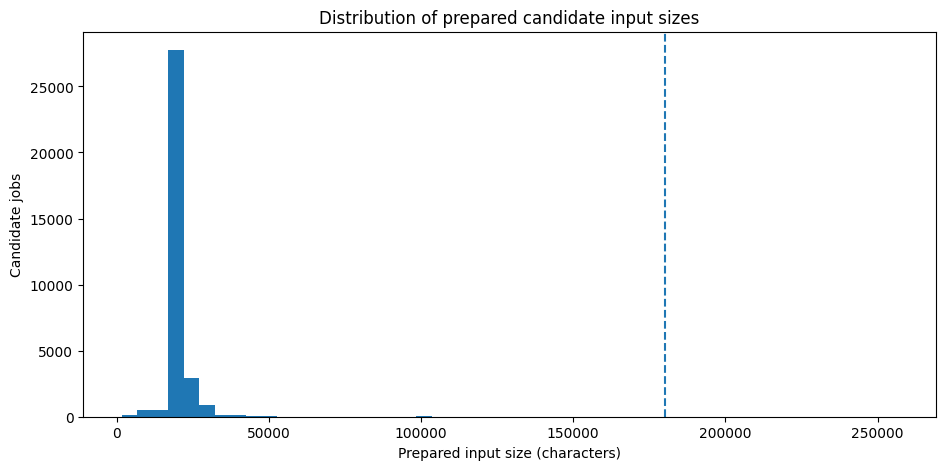

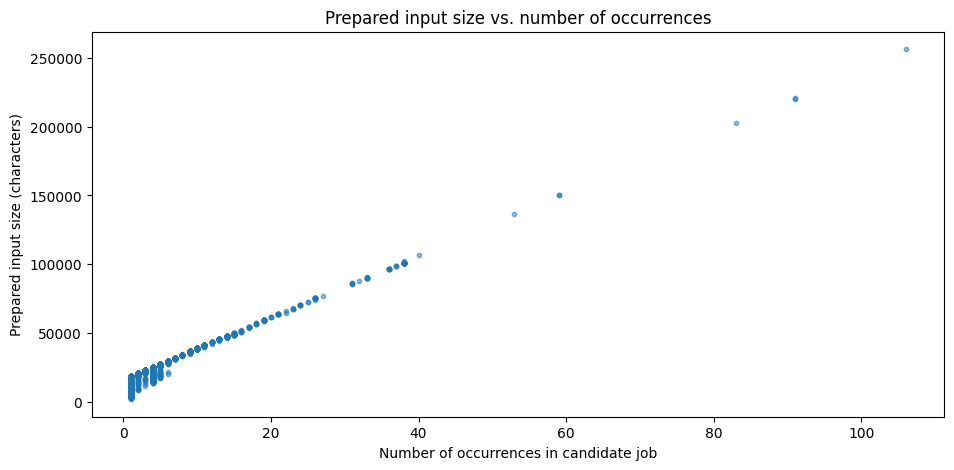

Prepared .txt folder: /home/edik/projects/eccjeu/data/temp/commission_registry
Tip: open any path from prepared_input_path to inspect the exact prebuilt text.


In [4]:
ready_registry = registry[registry["job_status"] == "ready"].copy()

prep_summary = (
    registry.groupby(["family", "job_status"], dropna=False)
    .size()
    .rename("jobs")
    .reset_index()
)

display(prep_summary)

if not ready_registry.empty:
    percentiles = ready_registry["prepared_chars"].astype(int).quantile(
        [0, 0.50, 0.90, 0.95, 0.99, 1.00]
    )
    print("Prepared-input character distribution (all ready jobs):")
    display(
        percentiles.rename("prepared_chars")
        .rename_axis("quantile")
        .reset_index()
    )

    by_family_chars = (
        ready_registry.groupby("family")["prepared_chars"]
        .agg(["count", "min", "median", "mean", "max"])
        .reset_index()
    )
    print("By family:")
    display(by_family_chars)

    print("Largest 30 prepared inputs:")
    display(
        ready_registry.sort_values("prepared_chars", ascending=False)[
            [
                "family",
                "source_document_key",
                "candidate",
                "n_occurrences",
                "prepared_chars",
                "original_document_chars",
                "prepared_input_source",
                "prepared_input_path",
            ]
        ].head(30)
    )

    plt.figure(figsize=(11, 5))
    plt.hist(ready_registry["prepared_chars"].astype(int), bins=50)
    plt.axvline(PREPARED_CHARS_WARNING, linestyle="--")
    plt.xlabel("Prepared input size (characters)")
    plt.ylabel("Candidate jobs")
    plt.title("Distribution of prepared candidate input sizes")
    plt.show()

    plt.figure(figsize=(11, 5))
    plt.scatter(
        ready_registry["n_occurrences"].astype(int),
        ready_registry["prepared_chars"].astype(int),
        s=10,
        alpha=0.5,
    )
    plt.xlabel("Number of occurrences in candidate job")
    plt.ylabel("Prepared input size (characters)")
    plt.title("Prepared input size vs. number of occurrences")
    plt.show()

    print("Prepared .txt folder:", TEMP_REGISTRY_DIR)
    print(
        "Tip: open any path from prepared_input_path to inspect the exact prebuilt text."
    )


## 4. Family-specific prompts and tiny structured output

The response intentionally contains only:

```json
{
  "valid": true,
  "identifiers": ["C-22/10", "C-23/10"]
}
```

Python already knows the family, document, candidate, occurrence count, source positions and
input path. The LLM is therefore not asked to reproduce any of those fields.

In [5]:
SYSTEM_MESSAGE = """
You are a careful legal-data extraction system for EU competition-law documents.
You are validating ONE regex candidate in ONE Commission document.
Use only the supplied text. Follow the requested JSON schema exactly.
Return JSON only.
""".strip()


COURT_CASE_PROMPT = r"""
TASK: VALIDATE ONE EU COURT-CASE REGEX CANDIDATE

You are given ONE normalized regex candidate and all of its occurrences in ONE
Commission document. The document introduction and ending are background only.
The occurrence windows are the primary evidence.

Decide whether the supplied candidate genuinely represents an EU Court case number
in this document.

IF VALID
Return the complete set of canonical Court case identifiers represented by citation
expressions that CONTAIN THIS candidate across the supplied occurrence windows.

This means:
- include the candidate itself in canonical form;
- expand clear `and` / `or` constructions;
- expand comma-separated coordinated lists;
- expand modest numeric ranges;
- inherit a shared C-/T- prefix or shared year only when the grammar is unambiguous;
- normalize obvious spacing/dash variants;
- remove procedural suffixes such as P, R, RENV, DEP or P-DEP from the canonical
  base case number.

Examples:
- `Joined Cases C-22/10 to 25/10`
  -> C-22/10, C-23/10, C-24/10, C-25/10
- `Cases C-21/77, 22/77 and 23/77`
  -> C-21/77, C-22/77, C-23/77
- `Cases 21, 22 or 23/77`
  -> 21/77, 22/77, 23/77 when the shared year is unambiguous.

COURT-CASE SCOPE
- Modern Court of Justice cases normally use C-...
- General Court / former Court of First Instance cases normally use T-...
- Historical genuine cases can be prefixless, e.g. 6/64 or 85/76.
- Prefixless NN/YY forms require stronger contextual support than explicit C-/T-
  forms because they can collide with dates, decision numbers and other references.

REJECT AS COURT CASES
- Commission decision references such as 88/22/EEC or 2003/706/EC;
- internal Commission competition case numbers such as IV/33.322, COMP/37.792,
  AT.39740;
- Council/Parliament acts;
- regulations/directives;
- OJ references;
- article/paragraph numbers, dates, years and unrelated administrative numbers.

IMPORTANT BOUNDARY
Do NOT harvest unrelated Court cases simply because they appear in an occurrence
window. Only return identifiers belonging to the citation expression that contains
the supplied candidate.

If at least one supplied occurrence genuinely uses the candidate as a Court case,
`valid` is true. If none do, `valid` is false and `identifiers` must be [].
""".strip()


COMMISSION_REFERENCE_PROMPT = r"""
TASK: VALIDATE ONE PUBLISHED COMMISSION DECISION-REFERENCE REGEX CANDIDATE

You are given ONE normalized regex candidate and all of its occurrences in ONE
Commission document. The document introduction and ending are background only.
The occurrence windows are the primary evidence.

A Commission reference is a published Commission decision / act reference such as:
- 88/22/EEC
- 2003/706/EC
- 2004/337/EC

Decide whether the supplied candidate genuinely refers to a COMMISSION decision /
act in this document rather than a lookalike number.

IF VALID
Return the complete set of canonical Commission references represented by citation
expressions that CONTAIN THIS candidate across the supplied occurrence windows.

This means:
- preserve or recover an EEC / EC / EU / ECSC suffix when the supplied text clearly
  shows it as part of the cited Commission reference;
- expand clear `and` / `or` constructions, comma lists and modest ranges when the
  shared year/suffix grammar is unambiguous;
- normalize obvious OCR/spacing variants conservatively.

POSITIVE CONTEXT
Strong evidence includes wording such as:
- `Commission Decision`;
- `Decision of the Commission`;
- wording that the Commission adopted, amended, annulled or cited the decision;
- a nearby EEC / EC / EU / ECSC suffix clearly attached to the decision number.

REJECT AS COMMISSION REFERENCES
- Court case numbers such as C-413/14, T-342/99 or historical 6/64;
- internal Commission competition case numbers such as IV/33.322, COMP/37.792,
  AT.39740;
- Council or Parliament decisions;
- regulations/directives when the number is not a Commission decision;
- OJ references, article/paragraph numbers, dates and unrelated numbers.

A reference to the source Commission decision itself is still a valid Commission
reference if the text genuinely uses that published decision identifier.

IMPORTANT BOUNDARY
Do NOT harvest unrelated Commission decision references simply because they appear
in an occurrence window. Only return identifiers belonging to the citation
expression that contains the supplied candidate.

If at least one supplied occurrence genuinely uses the candidate as a Commission
decision reference, `valid` is true. If none do, `valid` is false and
`identifiers` must be [].
""".strip()


COMMISSION_CASE_PROMPT = r"""
TASK: VALIDATE ONE INTERNAL COMMISSION COMPETITION-CASE REGEX CANDIDATE

You are given ONE normalized regex candidate and all of its occurrences in ONE
Commission document. The document introduction and ending are background only.
The occurrence windows are the primary evidence.

An internal Commission competition / administrative case identifier commonly uses:
- IV/33.322
- COMP/37.792
- AT.39740

Decide whether the supplied candidate genuinely represents this kind of Commission
competition case identifier in the document.

IF VALID
Return the complete set of canonical Commission case identifiers represented by
citation expressions that CONTAIN THIS candidate across the supplied occurrence
windows.

This means:
- preserve the meaningful IV/, COMP/ or AT. prefix;
- normalize obvious spacing/dash variants;
- expand clear `and` / `or` constructions and comma lists;
- inherit a shared prefix only when the grammar is unambiguous;
- expand a modest numeric range when the expression clearly denotes consecutive
  case identifiers.

Examples:
- `Cases COMP/37.792 and 37.793`
  -> COMP/37.792, COMP/37.793
- `AT.39740 or 39741`
  -> AT.39740, AT.39741 when the shared AT. prefix is unambiguous.

POSITIVE CONTEXT
Helpful wording can include:
- `Case`, `Commission case`, `competition case`, `antitrust case`;
- `procedure`, `proceedings`;
- explicit IV/, COMP/ or AT. formatting.

REJECT AS COMMISSION CASE NUMBERS
- Court case numbers such as C-413/14, T-342/99 or 6/64;
- published Commission decision references such as 88/22/EEC;
- Council/Parliament acts;
- regulations/directives;
- OJ references, article numbers, dates and unrelated file numbers.

A reference to the source Commission competition case itself is VALID. Do not reject
a case number merely because the document is the decision for that same case.

IMPORTANT BOUNDARY
Do NOT harvest unrelated Commission case numbers simply because they appear in an
occurrence window. Only return identifiers belonging to the citation expression
that contains the supplied candidate.

If at least one supplied occurrence genuinely uses the candidate as a Commission
competition case number, `valid` is true. If none do, `valid` is false and
`identifiers` must be [].
""".strip()


FAMILY_PROMPTS = {
    "court_case": COURT_CASE_PROMPT,
    "commission_reference": COMMISSION_REFERENCE_PROMPT,
    "commission_case": COMMISSION_CASE_PROMPT,
}


RESPONSE_JSON_SCHEMA = {
    "type": "object",
    "properties": {
        "valid": {
            "type": "boolean",
        },
        "identifiers": {
            "type": "array",
            "items": {
                "type": "string",
            },
        },
    },
    "required": [
        "valid",
        "identifiers",
    ],
    "additionalProperties": False,
}


def build_prompt(
    *,
    family: str,
    candidate: str,
    prepared_text: str,
) -> str:
    return f"""
{FAMILY_PROMPTS[family]}

SUPPLIED NORMALIZED REGEX CANDIDATE
{candidate}

PREPARED SOURCE TEXT
----- BEGIN PREPARED SOURCE -----
{prepared_text}
----- END PREPARED SOURCE -----

OUTPUT CONTRACT
Return exactly one JSON object with:
- valid: boolean
- identifiers: array of canonical identifiers

Do not return explanations, evidence quotations, metadata or markdown.
""".strip()

## 5. Parse and validate Gemma responses

In [6]:
def extract_json_object(raw_text: str) -> dict[str, Any]:
    text = clean_scalar(raw_text)

    if text.startswith("```"):
        text = re.sub(
            r"^```(?:json)?\s*",
            "",
            text,
            flags=re.IGNORECASE,
        )
        text = re.sub(
            r"\s*```$",
            "",
            text,
        )

    try:
        parsed = json.loads(text)
    except json.JSONDecodeError:
        start = text.find("{")
        end = text.rfind("}")

        if start < 0 or end < start:
            raise

        parsed = json.loads(
            text[start:end + 1]
        )

    if not isinstance(parsed, dict):
        raise ValueError(
            "Model output is not a JSON object."
        )

    return parsed


def normalize_court_identifier(value: Any) -> str:
    text = unicodedata.normalize(
        "NFKC",
        clean_scalar(value),
    )
    text = (
        text
        .replace("–", "-")
        .replace("—", "-")
        .replace("−", "-")
    )
    text = re.sub(r"\s+", " ", text).strip()

    # Remove common procedural suffixes from the canonical base case number.
    text = re.sub(
        r"\s+(?:P(?:-DEP)?|R(?:ENV)?|DEP)\b.*$",
        "",
        text,
        flags=re.IGNORECASE,
    ).strip()

    match = re.fullmatch(
        r"(?:(C|T)\s*[- ]\s*)?"
        r"(\d{1,4})\s*[/\-]\s*(\d{2,4})",
        text,
        flags=re.IGNORECASE,
    )

    if not match:
        return text

    prefix = match.group(1).upper() if match.group(1) else ""
    number = match.group(2)
    year = match.group(3)

    if len(year) == 4:
        year = year[-2:]

    return (
        f"{prefix}-{number}/{year}"
        if prefix
        else f"{number}/{year}"
    )


def normalize_commission_reference_identifier(value: Any) -> str:
    text = unicodedata.normalize(
        "NFKC",
        clean_scalar(value),
    ).upper()

    text = re.sub(r"\s+", "", text)

    match = re.fullmatch(
        r"(\d{2,4})/(\d{1,4})(?:/([A-Z]{2,5}))?",
        text,
    )

    if not match:
        return text

    year = match.group(1)
    number = match.group(2)
    suffix = match.group(3)

    return (
        f"{year}/{number}/{suffix}"
        if suffix
        else f"{year}/{number}"
    )


def normalize_commission_case_identifier(value: Any) -> str:
    text = unicodedata.normalize(
        "NFKC",
        clean_scalar(value),
    ).upper()

    text = (
        text
        .replace("–", "-")
        .replace("—", "-")
        .replace("−", "-")
    )
    text = re.sub(r"\s+", "", text)

    match = re.fullmatch(
        r"(IV|COMP)[/\.]?([0-9A-Z][0-9A-Z.\-/]*)",
        text,
    )

    if match:
        prefix = match.group(1)
        body = match.group(2).lstrip("/.")
        return f"{prefix}/{body}"

    match = re.fullmatch(
        r"AT[/\.]?([0-9A-Z][0-9A-Z.\-/]*)",
        text,
    )

    if match:
        body = match.group(1).lstrip("/.")
        return f"AT.{body}"

    return text


def normalize_identifier(
    family: str,
    value: Any,
) -> str:
    if family == "court_case":
        return normalize_court_identifier(value)
    if family == "commission_reference":
        return normalize_commission_reference_identifier(value)
    if family == "commission_case":
        return normalize_commission_case_identifier(value)
    return clean_scalar(value)


def validate_model_response(
    parsed: dict[str, Any],
    *,
    family: str,
    candidate: str,
) -> dict[str, Any]:
    valid = parsed.get("valid")

    if not isinstance(valid, bool):
        raise ValueError(
            "valid must be a boolean"
        )

    identifiers = parsed.get("identifiers")

    if not isinstance(identifiers, list):
        raise ValueError(
            "identifiers must be a list"
        )

    normalized = ordered_unique(
        normalize_identifier(
            family,
            value,
        )
        for value in identifiers
    )

    if valid and not normalized:
        raise ValueError(
            "valid=true requires at least one resolved identifier"
        )

    if not valid and normalized:
        raise ValueError(
            "valid=false requires identifiers=[]"
        )

    return {
        "valid": valid,
        "identifiers": normalized,
    }

## 6. Build lightweight candidate jobs from the prepared registry

In [7]:
def build_family_jobs(
    family: str,
    registry: pd.DataFrame,
) -> list[dict[str, Any]]:
    family_registry = registry[
        (registry["family"] == family)
        & (registry["job_status"] == "ready")
    ].copy()

    if MAX_JOBS_PER_FAMILY is not None:
        family_registry = family_registry.head(
            int(MAX_JOBS_PER_FAMILY)
        ).copy()

    jobs: list[dict[str, Any]] = []

    for _, row in family_registry.iterrows():
        jobs.append({
            "job_id": clean_scalar(row.get("job_id")),
            "family": family,
            "source_document_key": clean_scalar(
                row.get("source_document_key")
            ),
            "candidate": clean_scalar(
                row.get("candidate")
            ),
            "n_occurrences": safe_int(
                row.get("n_occurrences")
            ),
            "commission_source": clean_scalar(
                row.get("commission_source")
            ),
            "document_id": clean_document_id(
                row.get("document_id")
            ),
            "source_title": clean_scalar(
                row.get("source_title")
            ),
            "prepared_input_path": clean_scalar(
                row.get("prepared_input_path")
            ),
            "prepared_chars": safe_int(
                row.get("prepared_chars")
            ),
            "prepared_input_sha256": clean_scalar(
                row.get("prepared_input_sha256")
            ),
            "source_document_sha256": clean_scalar(
                row.get("source_document_sha256")
            ),
            "original_document_chars": safe_int(
                row.get("original_document_chars")
            ),
            "n_coordinate_mismatches": safe_int(
                row.get("n_coordinate_mismatches")
            ),
            "input_signature": clean_scalar(
                row.get("input_signature")
            ),
        })

    return jobs


def refresh_job_from_prepared_file(job: dict[str, Any]) -> dict[str, Any]:
    """Refresh size/hash/signature from the .txt file that will actually be sent."""
    refreshed = dict(job)
    input_path = Path(refreshed["prepared_input_path"])
    prepared_text = input_path.read_text(encoding="utf-8", errors="replace")
    prepared_sha = sha256_text(prepared_text)
    previous_sha = clean_scalar(refreshed.get("prepared_input_sha256"))

    # If somebody edited the .txt after the last token audit, do not keep stale
    # token counts/headroom. The inference cell will ask for the audit to be rerun.
    if previous_sha and previous_sha != prepared_sha:
        refreshed["prompt_tokens"] = None
        refreshed["model_max_len"] = None
        refreshed["headroom_after_reserved_output"] = None
        refreshed["safe_for_inference"] = None

    refreshed["prepared_chars"] = len(prepared_text)
    refreshed["prepared_input_sha256"] = prepared_sha
    refreshed["input_signature"] = job_signature(
        family=refreshed["family"],
        source_document_key=refreshed["source_document_key"],
        candidate=refreshed["candidate"],
        source_document_sha256=refreshed["source_document_sha256"],
        prepared_input_sha256=prepared_sha,
    )
    return refreshed


family_jobs = {
    family: build_family_jobs(
        family,
        registry,
    )
    for family in FAMILY_ORDER
}

for family in FAMILY_ORDER:
    jobs = family_jobs[family]
    print(
        FAMILY_CONFIG[family]["label"],
        "candidate jobs:",
        f"{len(jobs):,}",
        "| occurrences represented:",
        f"{sum(job['n_occurrences'] for job in jobs):,}",
    )

Court cases candidate jobs: 22,655 | occurrences represented: 39,047
Commission references candidate jobs: 3,371 | occurrences represented: 4,121
Commission cases candidate jobs: 7,110 | occurrences represented: 14,362


## 7. Exact prompt-size audit against the vLLM tokenizer

This uses the server's `/tokenize` endpoint with the same system and user messages as inference. It does **not** generate model output.


Token-auditing prepared prompts:   0%|          | 0/33136 [00:00<?, ?candidate/s]

Exact prompt-token distribution:


,quantile,prompt_tokens
0,0.00,1252.00
1,0.50,5751.00
2,0.90,7555.00
3,0.95,8594.25
4,0.99,11833.15
5,1.00,74132.00


Largest 30 actual prompts sent to chat/completions:


,family,source_document_key,candidate,n_occurrences,prepared_chars,prompt_tokens,model_max_len,headroom_after_reserved_output,safe_for_inference,prepared_input_path
5424,court_case,com_db_comp||2212,C-307/18,106,256334,74132,262144,186512,True,/home/edik/projects/eccjeu/data/temp/commissio...
1831,court_case,com_antitrust||com_antitrust__COM260__AT.37792...,C-3/37,91,220554,64640,262144,196004,True,/home/edik/projects/eccjeu/data/temp/commissio...
22118,court_case,com_db_comp||1855,C-3/37,91,220419,64572,262144,196072,True,/home/edik/projects/eccjeu/data/temp/commissio...
1590,court_case,com_antitrust||com_antitrust__COM260__AT.37792...,C-3/37,83,202596,62289,262144,198355,True,/home/edik/projects/eccjeu/data/temp/commissio...
22554,commission_case,com_antitrust||com_antitrust__COM260__AT.37792...,IV/C-3/37.345,59,150394,44671,262144,215973,True,/home/edik/projects/eccjeu/data/temp/commissio...
11943,commission_case,com_db_comp||1855,IV/C-3/37.345,59,150259,44602,262144,216042,True,/home/edik/projects/eccjeu/data/temp/commissio...
22456,commission_case,com_antitrust||com_antitrust__COM260__AT.37792...,IV/C-3/37.345,53,136751,42542,262144,218102,True,/home/edik/projects/eccjeu/data/temp/commissio...
28407,court_case,com_db_comp||1879,T-201/04,40,106621,34722,262144,225922,True,/home/edik/projects/eccjeu/data/temp/commissio...
31355,court_case,com_antitrust||com_antitrust__COM207__AT.37451...,C-1/37,37,98837,34618,262144,226026,True,/home/edik/projects/eccjeu/data/temp/commissio...
31956,court_case,com_antitrust||com_antitrust__COM217__AT.37578...,C-1/37,37,98837,34618,262144,226026,True,/home/edik/projects/eccjeu/data/temp/commissio...


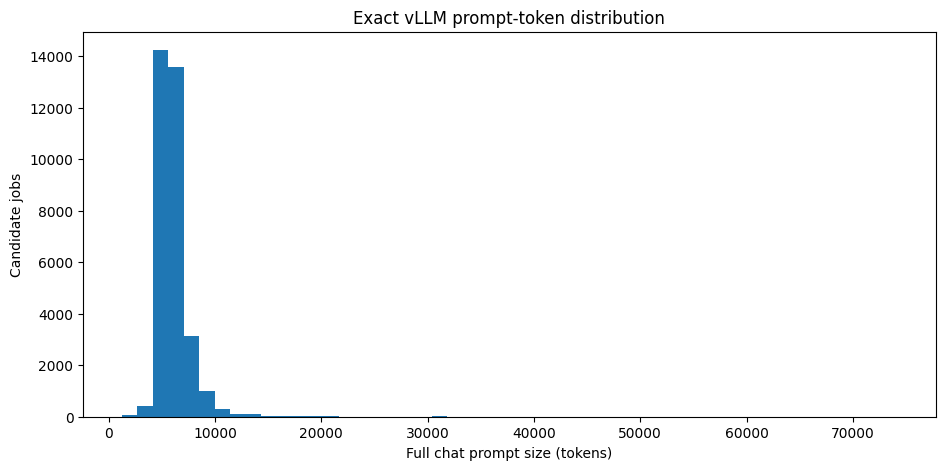

Unsafe / too close to model limit: 0 / 33,136
Wrote: /home/edik/projects/eccjeu/output/commission_regex/csv/commission_regex_prepared_input_audit.csv
Wrote: /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_prepared_input_audit.xlsx


In [8]:
def vllm_server_root() -> str:
    base = VLLM_BASE_URL.rstrip("/")
    if base.endswith("/v1"):
        return base[:-3]
    return base


def messages_for_job(job: dict[str, Any], prepared_text: str) -> list[dict[str, str]]:
    prompt = build_prompt(
        family=job["family"],
        candidate=job["candidate"],
        prepared_text=prepared_text,
    )
    return [
        {"role": "system", "content": SYSTEM_MESSAGE},
        {"role": "user", "content": prompt},
    ]


async def audit_one_job_tokens(
    job: dict[str, Any],
    client: httpx.AsyncClient,
    semaphore: asyncio.Semaphore,
) -> dict[str, Any]:
    row = {
        "job_id": job["job_id"],
        "family": job["family"],
        "source_document_key": job["source_document_key"],
        "candidate": job["candidate"],
        "n_occurrences": job["n_occurrences"],
        "prepared_input_path": job["prepared_input_path"],
        "prepared_chars": job["prepared_chars"],
        "prompt_tokens": None,
        "model_max_len": None,
        "headroom_after_reserved_output": None,
        "safe_for_inference": None,
        "tokenize_error": "",
    }

    try:
        refreshed = refresh_job_from_prepared_file(job)
        prepared_text = Path(refreshed["prepared_input_path"]).read_text(
            encoding="utf-8", errors="replace"
        )
        row["prepared_chars"] = len(prepared_text)
        messages = messages_for_job(refreshed, prepared_text)

        payload = {
            "model": MODEL,
            "messages": messages,
            "add_generation_prompt": True,
        }
        headers = {"Authorization": f"Bearer {VLLM_API_KEY}"}

        async with semaphore:
            response = await client.post(
                f"{vllm_server_root()}/tokenize",
                json=payload,
                headers=headers,
            )
        response.raise_for_status()
        body = response.json()

        prompt_tokens = safe_int(body.get("count"), -1)
        model_max_len = safe_int(body.get("max_model_len"), -1)
        row["prompt_tokens"] = prompt_tokens
        row["model_max_len"] = model_max_len

        if prompt_tokens >= 0 and model_max_len > 0:
            headroom = model_max_len - prompt_tokens - MAX_OUTPUT_TOKENS
            row["headroom_after_reserved_output"] = headroom
            row["safe_for_inference"] = headroom >= MIN_CONTEXT_HEADROOM_TOKENS

    except Exception as exc:
        row["tokenize_error"] = f"{type(exc).__name__}: {exc}"

    return row


async def audit_all_prompt_sizes() -> pd.DataFrame:
    jobs = [
        refresh_job_from_prepared_file(job)
        for family in FAMILY_ORDER
        for job in family_jobs[family]
    ]

    if not jobs:
        return pd.DataFrame()

    timeout = httpx.Timeout(REQUEST_TIMEOUT_SECONDS)
    semaphore = asyncio.Semaphore(max(1, TOKEN_AUDIT_WORKERS))

    async with httpx.AsyncClient(timeout=timeout) as client:
        tasks = [
            audit_one_job_tokens(job, client, semaphore)
            for job in jobs
        ]
        rows = []
        for coro in tqdm(
            asyncio.as_completed(tasks),
            total=len(tasks),
            desc="Token-auditing prepared prompts",
            unit="candidate",
        ):
            rows.append(await coro)

    return pd.DataFrame(rows)


INPUT_AUDIT_CSV = CSV_DIR / "commission_regex_prepared_input_audit.csv"
INPUT_AUDIT_XLSX = EXCEL_DIR / "commission_regex_prepared_input_audit.xlsx"

if RUN_EXACT_TOKEN_AUDIT:
    input_audit = await audit_all_prompt_sizes()
else:
    input_audit = pd.DataFrame()
    print("Exact token audit disabled. Character diagnostics above are still available.")

if not input_audit.empty:
    input_audit.to_csv(INPUT_AUDIT_CSV, index=False)
    with pd.ExcelWriter(INPUT_AUDIT_XLSX) as writer:
        input_audit.to_excel(writer, sheet_name="input_audit", index=False)

    good = input_audit[input_audit["prompt_tokens"].notna()].copy()
    errors = input_audit[input_audit["tokenize_error"].astype(str) != ""].copy()

    if not good.empty:
        print("Exact prompt-token distribution:")
        display(
            good["prompt_tokens"].astype(int).quantile(
                [0, 0.50, 0.90, 0.95, 0.99, 1.00]
            ).rename("prompt_tokens").rename_axis("quantile").reset_index()
        )

        print("Largest 30 actual prompts sent to chat/completions:")
        display(
            good.sort_values("prompt_tokens", ascending=False)[
                [
                    "family",
                    "source_document_key",
                    "candidate",
                    "n_occurrences",
                    "prepared_chars",
                    "prompt_tokens",
                    "model_max_len",
                    "headroom_after_reserved_output",
                    "safe_for_inference",
                    "prepared_input_path",
                ]
            ].head(30)
        )

        plt.figure(figsize=(11, 5))
        plt.hist(good["prompt_tokens"].astype(int), bins=50)
        plt.xlabel("Full chat prompt size (tokens)")
        plt.ylabel("Candidate jobs")
        plt.title("Exact vLLM prompt-token distribution")
        plt.show()

        unsafe = good[good["safe_for_inference"] == False]
        print(
            "Unsafe / too close to model limit:",
            f"{len(unsafe):,} / {len(good):,}",
        )
        if not unsafe.empty:
            display(unsafe.sort_values("prompt_tokens", ascending=False).head(50))

    if not errors.empty:
        print("Token-audit errors:", len(errors))
        display(errors.head(20))

    audit_by_id = input_audit.set_index("job_id").to_dict("index")
    for family in FAMILY_ORDER:
        enriched = []
        for job in family_jobs[family]:
            refreshed = refresh_job_from_prepared_file(job)
            audit = audit_by_id.get(job["job_id"], {})
            refreshed.update({
                "prompt_tokens": audit.get("prompt_tokens"),
                "model_max_len": audit.get("model_max_len"),
                "headroom_after_reserved_output": audit.get(
                    "headroom_after_reserved_output"
                ),
                "safe_for_inference": audit.get("safe_for_inference"),
            })
            enriched.append(refreshed)
        family_jobs[family] = enriched

    print("Wrote:", INPUT_AUDIT_CSV)
    print("Wrote:", INPUT_AUDIT_XLSX)


## 8. Bounded vLLM inference and append-only v8 checkpoints

Every worker reads exactly one prepared candidate file, sends one family-specific prompt,
writes the result to JSONL immediately, and releases the text.

`RUN_MODE="update"` skips only a successful job whose `input_signature` matches the
current v8 prepared input.

In [9]:
def utc_now_iso() -> str:
    return datetime.now(
        timezone.utc
    ).isoformat()


def load_latest_checkpoint(
    path: Path,
) -> dict[str, dict[str, Any]]:
    latest: dict[str, dict[str, Any]] = {}

    if not path.exists():
        return latest

    with path.open(
        "r",
        encoding="utf-8",
        errors="replace",
    ) as handle:
        for line_number, line in enumerate(
            handle,
            start=1,
        ):
            line = line.strip()

            if not line:
                continue

            try:
                record = json.loads(line)
            except json.JSONDecodeError as exc:
                print(
                    f"Skipping malformed checkpoint line "
                    f"{line_number} in {path.name}: {exc}"
                )
                continue

            if not isinstance(record, dict):
                continue

            job_id = clean_scalar(
                record.get("job_id")
            )
            if not job_id:
                continue

            previous = latest.get(job_id)

            if (
                previous is None
                or clean_scalar(record.get("classified_at"))
                >= clean_scalar(previous.get("classified_at"))
            ):
                latest[job_id] = record

    return latest


def append_checkpoint(
    path: Path,
    record: dict[str, Any],
) -> None:
    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    with path.open(
        "a",
        encoding="utf-8",
    ) as handle:
        handle.write(
            json.dumps(
                record,
                ensure_ascii=False,
                default=str,
            )
            + "\n"
        )
        handle.flush()
        os.fsync(handle.fileno())


async def call_vllm(
    client: httpx.AsyncClient,
    prompt: str,
) -> dict[str, str]:
    endpoint = (
        f"{VLLM_BASE_URL.rstrip('/')}"
        "/chat/completions"
    )

    payload = {
        "model": MODEL,
        "messages": [
            {
                "role": "system",
                "content": SYSTEM_MESSAGE,
            },
            {
                "role": "user",
                "content": prompt,
            },
        ],
        "temperature": TEMPERATURE,
        "max_tokens": MAX_OUTPUT_TOKENS,
        "structured_outputs": {
            "json": RESPONSE_JSON_SCHEMA,
        },
    }

    headers = {
        "Authorization": f"Bearer {VLLM_API_KEY}"
    }

    response = await client.post(
        endpoint,
        json=payload,
        headers=headers,
    )
    response.raise_for_status()

    body = response.json()
    choices = body.get("choices") or []

    if not choices:
        raise ValueError(
            "vLLM response contains no choices."
        )

    choice = choices[0]
    content = (
        choice.get("message", {})
        .get("content")
    )

    if not content:
        raise ValueError(
            "vLLM response contains no message content."
        )

    return {
        "content": str(content),
        "finish_reason": clean_scalar(
            choice.get("finish_reason")
        ),
    }


async def classify_one_job(
    job: dict[str, Any],
    client: httpx.AsyncClient,
) -> dict[str, Any]:
    common = {
        "job_id": job["job_id"],
        "family": job["family"],
        "source_document_key": job["source_document_key"],
        "candidate": job["candidate"],
        "n_occurrences": job["n_occurrences"],
        "commission_source": job["commission_source"],
        "document_id": job["document_id"],
        "source_title": job["source_title"],
        "prepared_input_path": job["prepared_input_path"],
        "prepared_chars": job["prepared_chars"],
        "prepared_input_sha256": job.get("prepared_input_sha256", ""),
        "prompt_tokens": job.get("prompt_tokens"),
        "model_max_len": job.get("model_max_len"),
        "headroom_after_reserved_output": job.get("headroom_after_reserved_output"),
        "original_document_chars": job["original_document_chars"],
        "n_coordinate_mismatches": job["n_coordinate_mismatches"],
        "input_signature": job["input_signature"],
        "model": MODEL,
    }

    input_path = Path(
        job["prepared_input_path"]
    )

    try:
        prepared_text = input_path.read_text(
            encoding="utf-8",
            errors="replace",
        )
    except Exception as exc:
        return {
            **common,
            "llm_status": "error",
            "llm_error": (
                f"Could not read prepared input: "
                f"{type(exc).__name__}: {exc}"
            ),
            "classified_at": utc_now_iso(),
            "attempts": 0,
            "finish_reason": "",
            "raw_response": "",
            "parsed_response": None,
        }

    if not prepared_text.strip():
        return {
            **common,
            "llm_status": "error",
            "llm_error": "Prepared input is empty.",
            "classified_at": utc_now_iso(),
            "attempts": 0,
            "finish_reason": "",
            "raw_response": "",
            "parsed_response": None,
        }

    actual_sha = sha256_text(prepared_text)
    expected_sha = clean_scalar(job.get("prepared_input_sha256"))
    if len(prepared_text) != job["prepared_chars"] or (expected_sha and actual_sha != expected_sha):
        return {
            **common,
            "llm_status": "error",
            "llm_error": (
                "Prepared input changed after the job was refreshed. "
                "Rerun this family cell so the on-disk .txt is refreshed before sending."
            ),
            "classified_at": utc_now_iso(),
            "attempts": 0,
            "finish_reason": "",
            "raw_response": "",
            "parsed_response": None,
        }

    if RUN_EXACT_TOKEN_AUDIT and job.get("prompt_tokens") is None:
        return {
            **common,
            "llm_status": "token_audit_required",
            "llm_error": (
                "Prepared input has no current exact token audit. "
                "If you edited a prepared .txt, rerun the exact prompt-size audit cell first."
            ),
            "classified_at": utc_now_iso(),
            "attempts": 0,
            "finish_reason": "",
            "raw_response": "",
            "parsed_response": None,
        }

    if SKIP_UNSAFE_INPUTS and job.get("safe_for_inference") is False:
        return {
            **common,
            "llm_status": "input_too_long",
            "llm_error": (
                "Exact /tokenize audit leaves less than "
                f"{MIN_CONTEXT_HEADROOM_TOKENS:,} tokens after reserving "
                f"MAX_OUTPUT_TOKENS={MAX_OUTPUT_TOKENS:,}. Request not sent."
            ),
            "classified_at": utc_now_iso(),
            "attempts": 0,
            "finish_reason": "",
            "raw_response": "",
            "parsed_response": None,
        }

    prompt = build_prompt(
        family=job["family"],
        candidate=job["candidate"],
        prepared_text=prepared_text,
    )

    last_error = ""
    last_raw_response = ""
    last_finish_reason = ""

    for attempt in range(
        1,
        MAX_RETRIES + 2,
    ):
        try:
            result = await call_vllm(
                client,
                prompt,
            )

            last_raw_response = result["content"]
            last_finish_reason = result["finish_reason"]

            if result["finish_reason"] == "length":
                return {
                    **common,
                    "llm_status": "output_too_long",
                    "llm_error": (
                        "Model response reached MAX_OUTPUT_TOKENS="
                        f"{MAX_OUTPUT_TOKENS:,}; not retried automatically."
                    ),
                    "classified_at": utc_now_iso(),
                    "attempts": attempt,
                    "finish_reason": result["finish_reason"],
                    "raw_response": result["content"],
                    "parsed_response": None,
                }

            parsed = extract_json_object(
                result["content"]
            )

            validated = validate_model_response(
                parsed,
                family=job["family"],
                candidate=job["candidate"],
            )

            return {
                **common,
                "llm_status": "ok",
                "llm_error": "",
                "classified_at": utc_now_iso(),
                "attempts": attempt,
                "finish_reason": result["finish_reason"],
                "raw_response": result["content"],
                "parsed_response": validated,
            }

        except Exception as exc:
            last_error = (
                f"{type(exc).__name__}: {exc}"
            )

            if attempt <= MAX_RETRIES:
                await asyncio.sleep(
                    min(2 ** attempt, 10)
                )

    return {
        **common,
        "llm_status": "error",
        "llm_error": last_error,
        "classified_at": utc_now_iso(),
        "attempts": MAX_RETRIES + 1,
        "finish_reason": last_finish_reason,
        "raw_response": last_raw_response,
        "parsed_response": None,
    }


async def classify_family(
    family: str,
    jobs: list[dict[str, Any]],
    workers: int = WORKER_COUNT,
) -> list[dict[str, Any]]:
    config = FAMILY_CONFIG[family]
    checkpoint_path = config["checkpoint"]

    # The prepared .txt files are the source of truth at inference time.
    # Manual edits made after preparation are picked up here and produce a new
    # input signature, so update mode will not incorrectly reuse an old result.
    jobs = [refresh_job_from_prepared_file(job) for job in jobs]

    if RUN_MODE == "redo_all" and checkpoint_path.exists():
        checkpoint_path.unlink()

    latest = load_latest_checkpoint(
        checkpoint_path
    )

    current_job_ids = {
        job["job_id"]
        for job in jobs
    }

    if RUN_MODE == "rebuild_exports":
        return [
            record
            for job_id, record in latest.items()
            if job_id in current_job_ids
        ]

    pending: list[dict[str, Any]] = []

    for job in jobs:
        existing = latest.get(
            job["job_id"]
        )

        is_current_success = (
            existing is not None
            and existing.get("llm_status") == "ok"
            and clean_scalar(
                existing.get("input_signature")
            )
            == job["input_signature"]
        )

        if RUN_MODE == "update" and is_current_success:
            continue

        pending.append(job)

    pending.sort(
        key=lambda job: (
            safe_int(job.get("prompt_tokens"), 10**12)
            if job.get("prompt_tokens") is not None
            else 10**12
        )
    )

    print()
    print("=" * 80)
    print(
        f"{config['label'].upper()} — V8 CANDIDATE-LEVEL PASS"
    )
    print("=" * 80)
    print("Total candidate jobs:", f"{len(jobs):,}")
    print("Jobs requiring Gemma:", f"{len(pending):,}")
    print("Bounded workers:", workers)

    if not pending:
        return [
            record
            for job_id, record in load_latest_checkpoint(
                checkpoint_path
            ).items()
            if job_id in current_job_ids
        ]

    queue: asyncio.Queue = asyncio.Queue()

    for job in pending:
        queue.put_nowait(job)

    write_lock = asyncio.Lock()
    large_request_gate = asyncio.Semaphore(
        max(1, MAX_CONCURRENT_LARGE_REQUESTS)
    )
    progress = tqdm(
        total=len(pending),
        desc=config["label"],
        unit="candidate",
    )

    timeout = httpx.Timeout(
        REQUEST_TIMEOUT_SECONDS
    )

    async with httpx.AsyncClient(
        timeout=timeout,
    ) as client:

        async def worker_loop() -> None:
            while True:
                try:
                    job = queue.get_nowait()
                except asyncio.QueueEmpty:
                    return

                try:
                    prompt_tokens = safe_int(job.get("prompt_tokens"), 0)
                    if prompt_tokens >= LARGE_PROMPT_TOKENS:
                        async with large_request_gate:
                            result = await classify_one_job(
                                job,
                                client,
                            )
                    else:
                        result = await classify_one_job(
                            job,
                            client,
                        )

                    async with write_lock:
                        append_checkpoint(
                            checkpoint_path,
                            result,
                        )
                finally:
                    queue.task_done()
                    progress.update(1)

        tasks = [
            asyncio.create_task(
                worker_loop()
            )
            for _ in range(
                max(1, int(workers))
            )
        ]

        await queue.join()
        await asyncio.gather(*tasks)

    progress.close()

    current_latest = load_latest_checkpoint(
        checkpoint_path
    )

    return [
        current_latest[job_id]
        for job_id in current_job_ids
        if job_id in current_latest
    ]


classification_records: dict[
    str,
    list[dict[str, Any]],
] = {}

## 9A. Run Court-case validation

This cell runs only the Court family with the Court-specific prompt.

In [10]:
classification_records["court_case"] = await classify_family(
    "court_case",
    family_jobs["court_case"],
    workers=WORKER_COUNT,
)

court_latest = {
    job_id: record
    for job_id, record in load_latest_checkpoint(
        FAMILY_CONFIG["court_case"]["checkpoint"]
    ).items()
    if job_id in {job["job_id"] for job in family_jobs["court_case"]}
}

print(
    pd.Series(
        [
            record.get("llm_status", "missing")
            for record in court_latest.values()
        ],
        dtype="object",
    ).value_counts(dropna=False)
)


COURT CASES — V8 CANDIDATE-LEVEL PASS
Total candidate jobs: 22,655
Jobs requiring Gemma: 22,554
Bounded workers: 8


Court cases:   0%|          | 0/22554 [00:00<?, ?candidate/s]

ok       22651
error        4
Name: count, dtype: int64


## 9B. Run published Commission-reference validation

This cell runs only the Commission decision-reference family with its specialised prompt.

In [11]:
classification_records["commission_reference"] = await classify_family(
    "commission_reference",
    family_jobs["commission_reference"],
    workers=WORKER_COUNT,
)

commission_reference_latest = {
    job_id: record
    for job_id, record in load_latest_checkpoint(
        FAMILY_CONFIG["commission_reference"]["checkpoint"]
    ).items()
    if job_id in {
        job["job_id"]
        for job in family_jobs["commission_reference"]
    }
}

print(
    pd.Series(
        [
            record.get("llm_status", "missing")
            for record in commission_reference_latest.values()
        ],
        dtype="object",
    ).value_counts(dropna=False)
)


COMMISSION REFERENCES — V8 CANDIDATE-LEVEL PASS
Total candidate jobs: 3,371
Jobs requiring Gemma: 3,371
Bounded workers: 8


Commission references:   0%|          | 0/3371 [00:00<?, ?candidate/s]

ok    3371
Name: count, dtype: int64


## 9C. Run internal Commission competition-case validation

This cell runs only the IV/ / COMP/ / AT. family with its specialised prompt.

In [12]:
classification_records["commission_case"] = await classify_family(
    "commission_case",
    family_jobs["commission_case"],
    workers=WORKER_COUNT,
)

commission_case_latest = {
    job_id: record
    for job_id, record in load_latest_checkpoint(
        FAMILY_CONFIG["commission_case"]["checkpoint"]
    ).items()
    if job_id in {
        job["job_id"]
        for job in family_jobs["commission_case"]
    }
}

print(
    pd.Series(
        [
            record.get("llm_status", "missing")
            for record in commission_case_latest.values()
        ],
        dtype="object",
    ).value_counts(dropna=False)
)


COMMISSION CASES — V8 CANDIDATE-LEVEL PASS
Total candidate jobs: 7,110
Jobs requiring Gemma: 7,110
Bounded workers: 8


Commission cases:   0%|          | 0/7110 [00:00<?, ?candidate/s]

ok    7110
Name: count, dtype: int64


## 10. Rebuild v8 family outputs

Each successful candidate job produces:

- one candidate-validation row;
- zero or more exploded canonical identifier rows.

The candidate table is the primary audit table. The exploded identifier table is useful
for downstream citation/network construction.

In [13]:
def current_family_record_map(
    family: str,
) -> dict[str, dict[str, Any]]:
    latest = load_latest_checkpoint(
        FAMILY_CONFIG[family]["checkpoint"]
    )

    current_jobs = {
        job["job_id"]: job
        for job in family_jobs[family]
    }

    out: dict[str, dict[str, Any]] = {}

    for job_id, job in current_jobs.items():
        record = latest.get(job_id)

        if record is None:
            continue

        if clean_scalar(
            record.get("input_signature")
        ) != job["input_signature"]:
            continue

        out[job_id] = record

    return out


def build_family_outputs(
    family: str,
) -> dict[str, pd.DataFrame]:
    current_records = current_family_record_map(
        family
    )

    candidate_rows: list[dict[str, Any]] = []
    identifier_rows: list[dict[str, Any]] = []
    error_rows: list[dict[str, Any]] = []

    for job in family_jobs[family]:
        record = current_records.get(
            job["job_id"]
        )

        base = {
            "source_document_key": job["source_document_key"],
            "commission_source": job["commission_source"],
            "document_id": job["document_id"],
            "source_title": job["source_title"],
            "family": family,
            "job_id": job["job_id"],
            "regex_candidate": job["candidate"],
            "n_occurrences": job["n_occurrences"],
            "prepared_input_path": job["prepared_input_path"],
            "prepared_chars": job["prepared_chars"],
            "prompt_tokens": job.get("prompt_tokens"),
            "model_max_len": job.get("model_max_len"),
            "headroom_after_reserved_output": job.get("headroom_after_reserved_output"),
            "original_document_chars": job["original_document_chars"],
            "n_coordinate_mismatches": job["n_coordinate_mismatches"],
            "input_signature": job["input_signature"],
        }

        if record is None:
            error_rows.append({
                **base,
                "llm_status": "missing",
                "llm_error": "No current checkpoint record",
                "finish_reason": "",
                "classified_at": "",
            })
            continue

        if record.get("llm_status") != "ok":
            error_rows.append({
                **base,
                "llm_status": clean_scalar(
                    record.get("llm_status")
                ),
                "llm_error": clean_scalar(
                    record.get("llm_error")
                ),
                "finish_reason": clean_scalar(
                    record.get("finish_reason")
                ),
                "classified_at": clean_scalar(
                    record.get("classified_at")
                ),
            })
            continue

        parsed = record.get(
            "parsed_response"
        )

        if not isinstance(parsed, dict):
            error_rows.append({
                **base,
                "llm_status": "error",
                "llm_error": "Successful checkpoint has no parsed_response",
                "finish_reason": clean_scalar(
                    record.get("finish_reason")
                ),
                "classified_at": clean_scalar(
                    record.get("classified_at")
                ),
            })
            continue

        valid = bool(parsed.get("valid"))
        identifiers = ordered_unique(
            parsed.get("identifiers") or []
        )

        candidate_rows.append({
            **base,
            "candidate_is_valid": valid,
            "resolved_identifiers_json": json.dumps(
                identifiers,
                ensure_ascii=False,
            ),
            "n_resolved_identifiers": len(identifiers),
            "expansion_detected": bool(
                valid and len(identifiers) > 1
            ),
            "model": clean_scalar(
                record.get("model")
            ),
            "classified_at": clean_scalar(
                record.get("classified_at")
            ),
            "attempts": safe_int(
                record.get("attempts")
            ),
            "finish_reason": clean_scalar(
                record.get("finish_reason")
            ),
        })

        for identifier in identifiers:
            identifier_rows.append({
                **base,
                "resolved_identifier": identifier,
                "candidate_is_valid": valid,
                "expansion_detected": bool(
                    len(identifiers) > 1
                ),
                "classified_at": clean_scalar(
                    record.get("classified_at")
                ),
            })

    return {
        "candidate_validation": pd.DataFrame(candidate_rows),
        "resolved_identifiers": pd.DataFrame(identifier_rows),
        "errors": pd.DataFrame(error_rows),
    }


family_outputs = {
    family: build_family_outputs(
        family
    )
    for family in FAMILY_ORDER
}


summary_rows: list[dict[str, Any]] = []

for family in FAMILY_ORDER:
    outputs = family_outputs[family]
    candidates = outputs["candidate_validation"]
    errors = outputs["errors"]

    summary_rows.append({
        "family": family,
        "candidate_jobs": len(family_jobs[family]),
        "successful_candidates": len(candidates),
        "valid_candidates": (
            int(candidates["candidate_is_valid"].sum())
            if not candidates.empty
            else 0
        ),
        "invalid_candidates": (
            int((~candidates["candidate_is_valid"]).sum())
            if not candidates.empty
            else 0
        ),
        "expanded_candidates": (
            int(candidates["expansion_detected"].sum())
            if not candidates.empty
            else 0
        ),
        "resolved_identifier_rows": len(
            outputs["resolved_identifiers"]
        ),
        "errors_or_missing": len(errors),
    })

    with pd.ExcelWriter(
        FAMILY_CONFIG[family]["output_xlsx"]
    ) as writer:
        outputs["candidate_validation"].to_excel(
            writer,
            sheet_name="candidate_validation",
            index=False,
        )
        outputs["resolved_identifiers"].to_excel(
            writer,
            sheet_name="resolved_identifiers",
            index=False,
        )
        outputs["errors"].to_excel(
            writer,
            sheet_name="errors",
            index=False,
        )

    outputs["candidate_validation"].to_csv(
        FAMILY_CONFIG[family]["output_csv"],
        index=False,
    )

summary_df = pd.DataFrame(summary_rows)

with pd.ExcelWriter(SUMMARY_XLSX) as writer:
    summary_df.to_excel(
        writer,
        sheet_name="summary",
        index=False,
    )

    for family in FAMILY_ORDER:
        family_outputs[family]["candidate_validation"].to_excel(
            writer,
            sheet_name=f"{family[:22]}_candidates",
            index=False,
        )

display(summary_df)

print("\nWrote v8 family exports and summary:")
for family in FAMILY_ORDER:
    print(" ", FAMILY_CONFIG[family]["output_xlsx"])
    print(" ", FAMILY_CONFIG[family]["output_csv"])
print(" ", SUMMARY_XLSX)

,family,candidate_jobs,successful_candidates,valid_candidates,invalid_candidates,expanded_candidates,resolved_identifier_rows,errors_or_missing
0,court_case,22655,22651,20474,2177,8448,110585,4
1,commission_reference,3371,3371,2457,914,4,2461,0
2,commission_case,7110,7110,6969,141,496,7852,0



Wrote v8 family exports and summary:
  /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_court_case_classification.xlsx
  /home/edik/projects/eccjeu/output/commission_regex/csv/commission_regex_court_cases_classified.csv
  /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_commission_reference_classification.xlsx
  /home/edik/projects/eccjeu/output/commission_regex/csv/commission_regex_commission_references_classified.csv
  /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_commission_case_classification.xlsx
  /home/edik/projects/eccjeu/output/commission_regex/csv/commission_regex_commission_cases_classified.csv
  /home/edik/projects/eccjeu/output/commission_regex/excel/commission_regex_classification_summary.xlsx


## 11. Quality-control views

In [14]:
for family in FAMILY_ORDER:
    outputs = family_outputs[family]

    print()
    print("=" * 80)
    print(FAMILY_CONFIG[family]["label"].upper())
    print("=" * 80)

    candidates = outputs["candidate_validation"]

    if not candidates.empty:
        print("Candidate validity:")
        display(
            candidates[
                "candidate_is_valid"
            ]
            .value_counts(dropna=False)
            .rename_axis("candidate_is_valid")
            .reset_index(name="jobs")
        )

        print("Expansion detected:")
        display(
            candidates[
                "expansion_detected"
            ]
            .value_counts(dropna=False)
            .rename_axis("expansion_detected")
            .reset_index(name="jobs")
        )

        print("Sample expanded candidates:")
        display(
            candidates[
                candidates["expansion_detected"]
            ][
                [
                    "source_document_key",
                    "regex_candidate",
                    "n_occurrences",
                    "resolved_identifiers_json",
                    "prepared_input_path",
                ]
            ].head(30)
        )

    if not outputs["errors"].empty:
        print("Errors / missing:")
        display(
            outputs["errors"].head(30)
        )


COURT CASES
Candidate validity:


,candidate_is_valid,jobs
0,True,20474
1,False,2177


Expansion detected:


,expansion_detected,jobs
0,False,14203
1,True,8448


Sample expanded candidates:


...

,candidate_is_valid,jobs
0,True,6969
1,False,141


Expansion detected:


,expansion_detected,jobs
0,False,6614
1,True,496


Sample expanded candidates:


,source_document_key,regex_candidate,n_occurrences,resolved_identifiers_json,prepared_input_path
9,com_antitrust||com_antitrust__COM1004__AT.4046...,AT.40703 13,1,"[""AT.40462"", ""AT.40703""]",/home/edik/projects/eccjeu/data/temp/commissio...
16,com_antitrust||com_antitrust__COM1056__AT.4051...,AT.39861,1,"[""AT.39861"", ""AT.39914""]",/home/edik/projects/eccjeu/data/temp/commissio...
17,com_antitrust||com_antitrust__COM1056__AT.4051...,AT.39914,1,"[""AT.39861"", ""AT.39914""]",/home/edik/projects/eccjeu/data/temp/commissio...
79,com_antitrust||com_antitrust__COM1129__AT.4070...,AT.40462,5,"[""AT.40462"", ""AT.40703""]",/home/edik/projects/eccjeu/data/temp/commissio...
83,com_antitrust||com_antitrust__COM1129__AT.4070...,AT.40703 13,1,"[""AT.40462"", ""AT.40703""]",/home/edik/projects/eccjeu/data/temp/commissio...
140,com_antitrust||com_antitrust__COM15__AT.33708_...,IV/F-3/33.708,2,"[""IV/F-3/33.708"", ""IV/F-3/33.709"", ""IV/F-3/33....",/home/edik/projects/eccjeu/data/temp/commissio...
141,com_antitrust||com_antitrust__COM15__AT.33708_...,IV/F-3/33.709,2,"[""IV/F-3/33.708"", ""IV/F-3/33.709"", ""IV/F-3/33....",/home/edik/projects/eccjeu/data/temp/commissio...
142,com_antitrust||com_antitrust__COM15__AT.33708_...,IV/F-3/33.710,2,"[""IV/F-3/33.708"", ""IV/F-3/33.709"", ""IV/F-3/33....",/home/edik/projects/eccjeu/data/temp/commissio...
143,com_antitrust||com_antitrust__COM15__AT.33708_...,IV/F-3/33.711,2,"[""IV/F-3/33.708"", ""IV/F-3/33.709"", ""IV/F-3/33....",/home/edik/projects/eccjeu/data/temp/commissio...
161,com_antitrust||com_antitrust__COM182__AT.36957...,IV/26.894,1,"[""IV/26.894"", ""IV/26.876"", ""IV/26.892""]",/home/edik/projects/eccjeu/data/temp/commissio...


## Output layout

Notebook:

```text
classify_commission_documents_v8.ipynb
```

Prepared candidate-level inputs:

```text
data/temp/commission_registry/
  registry.csv
  court_case/
    <document>__<candidate>__<hash>.txt
  commission_reference/
    <document>__<candidate>__<hash>.txt
  commission_case/
    <document>__<candidate>__<hash>.txt
```

v8 checkpoints:

```text
output/commission_regex/jsonl/
  commission_regex_court_case_classification.jsonl
  commission_regex_commission_reference_classification.jsonl
  commission_regex_commission_case_classification.jsonl
```

v8 registry and exports:

```text
output/commission_regex/excel/
  commission_regex_candidate_registry.xlsx
  commission_regex_court_case_classification.xlsx
  commission_regex_commission_reference_classification.xlsx
  commission_regex_commission_case_classification.xlsx
  commission_regex_classification_summary.xlsx

output/commission_regex/csv/
  commission_regex_candidate_registry.csv
  commission_regex_court_cases_classified.csv
  commission_regex_commission_references_classified.csv
  commission_regex_commission_cases_classified.csv
```

The v8 checkpoints and exports are deliberately versioned so that the earlier v6
classification results cannot contaminate the new candidate-level run.